# Konfidens, gerbang sigmoid, dan MF dengan suku aspek

[![Buka di Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/imamrozi/recsys-hibrida-multisinyal-notebooks/blob/main/notebooks/bab03_sentiment_aware/02_konfidens_gerbang_mf_aspek.ipynb)

**Buku pendamping:** *Sistem Rekomendasi Hibrida Multi-Sinyal: Rating, Sentimen, dan Emosi* · Bab 3 · Kode 3.4.1 dan 3.5.1

**Tujuan belajar**

- Menghitung konfidens softmax dan melihat batasnya pada klasifikator lima kelas.
- Memahami gerbang sigmoid g(c) dan peran τ serta k.
- Membandingkan MF, MF+ABSA, dan MF+CA-ABSA pada kualitas ekstraksi yang berbeda.

> **Catatan jujur.** Semua data di notebook ini **simulasi** dan dibuat agar mudah dijalankan (CPU, hitungan detik). Angka yang keluar menunjukkan *perilaku metode*, bukan hasil empiris pada dataset nyata, dan tidak boleh dikutip sebagai bukti. Kode bersifat ilustratif dan **belum production-ready** (tanpa validasi masukan, tanpa uji beban).

> Eksperimen B dan C memakai **simulasi dengan asumsi eksplisit** (lihat docstring `simulasi_ulasan`). Hasilnya menunjukkan *kapan* gerbang membantu atau tidak, bukan seberapa besar manfaatnya pada dataset nyata.

## 1. Kode dari buku: konfidens dan gerbang (Kode 3.4.1)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.special import softmax


def conf_softmax(z):
    """Pers. (3-2): c = max softmax(z). Untuk C kelas, c berada di [1/C, 1]."""
    return softmax(z, axis=1).max(axis=1)


def gate(c, tau=0.5, k=10.0):
    """Pers. (3-4): g(c) = 1 / (1 + exp(-k (c - tau)))."""
    return 1.0 / (1.0 + np.exp(-k * (c - tau)))

### Eksperimen A: apa arti konfidens softmax?

Untuk 5 kelas, konfidens minimum adalah 1/5 = 0,2 (tebakan seragam). Kita variasikan "ketajaman" logit dan lihat konfidensnya, lalu gambar gerbang untuk beberapa pasangan (τ, k).

             c_rata2  c_min  c_maks  g(c)_rata2
skala_logit                                    
0.1            0.224  0.201   0.286       0.060
0.5            0.330  0.206   0.719       0.172
1.0            0.460  0.211   0.961       0.410
2.0            0.643  0.223   0.999       0.701
4.0            0.802  0.248   1.000       0.869


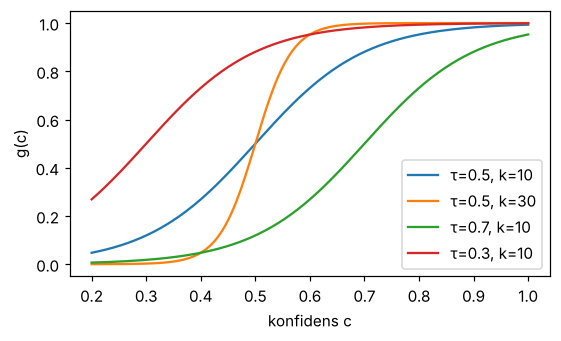

In [2]:
rng = np.random.default_rng(0)
z0 = rng.normal(0, 1, (5000, 5))
rows = []
for skala in (0.1, 0.5, 1, 2, 4):
    c = conf_softmax(skala * z0)
    rows.append({"skala_logit": skala, "c_rata2": c.mean(), "c_min": c.min(), "c_maks": c.max(),
                 "g(c)_rata2": gate(c).mean()})
print(pd.DataFrame(rows).set_index("skala_logit").round(3))

cc = np.linspace(0.2, 1, 200)
fig, ax = plt.subplots(figsize=(5.2, 3.2))
for tau, k in ((0.5, 10), (0.5, 30), (0.7, 10), (0.3, 10)):
    ax.plot(cc, gate(cc, tau, k), label=f"τ={tau}, k={k}")
ax.set(xlabel="konfidens c", ylabel="g(c)")
ax.legend()
fig.tight_layout()
assert conf_softmax(0.1 * z0).min() >= 0.2 - 1e-9

**Interpretasi.** Konfidens softmax dibatasi dari bawah oleh 1/C. Logit yang tajam menghasilkan konfidens tinggi *tanpa jaminan* bahwa klasifikator benar, karena softmax tidak terkalibrasi. τ menggeser titik tengah gerbang dan *k* mengatur ketajamannya: *k* besar membuat gerbang hampir seperti sakelar.

## 2. Kode dari buku: MF dengan suku aspek (Kode 3.5.1)

In [3]:
class AspectMF:
    """r_hat = mu + b_u + b_i + p_u.q_i + sum_k a_u^k * s_ui^k  [Pers. 3-6]"""

    def __init__(self, n_users, n_items, n_aspects, d=8, lr=0.02, reg=0.02,
                 use_aspect=True, seed=0):
        rng = np.random.default_rng(seed)
        self.P = rng.normal(0, 0.1, (n_users, d))
        self.Q = rng.normal(0, 0.1, (n_items, d))
        self.bu, self.bi = np.zeros(n_users), np.zeros(n_items)
        self.A = np.zeros((n_users, n_aspects))
        self.mu, self.lr, self.reg = 0.0, lr, reg
        self.use_aspect, self.rng = use_aspect, rng

    def predict(self, u, i, s):
        out = self.mu + self.bu[u] + self.bi[i] + (self.P[u] * self.Q[i]).sum(1)
        return out + (self.A[u] * s).sum(1) if self.use_aspect else out

    def fit(self, u, i, r, s, epochs=40, batch=256):
        self.mu = r.mean()
        lr, lam = self.lr, self.reg
        for _ in range(epochs):
            for idx in np.array_split(self.rng.permutation(len(r)),
                                      max(1, len(r) // batch)):
                ub, ib, sb = u[idx], i[idx], s[idx]
                e = (r[idx] - self.predict(ub, ib, sb))[:, None]  # galat
                pu, qi = self.P[ub].copy(), self.Q[ib].copy()
                np.add.at(self.bu, ub, lr * (e[:, 0] - lam * self.bu[ub]))
                np.add.at(self.bi, ib, lr * (e[:, 0] - lam * self.bi[ib]))
                np.add.at(self.P, ub, lr * (e * qi - lam * pu))
                np.add.at(self.Q, ib, lr * (e * pu - lam * qi))
                if self.use_aspect:  # d r_hat / d a_u^k = s_ui^k
                    np.add.at(self.A, ub, lr * (e * sb - lam * self.A[ub]))
        return self

Tiga varian dibedakan oleh masukan suku aspek: **MF** (tanpa suku aspek), **MF+ABSA** (`s` apa adanya), dan **MF+CA-ABSA** (`g(c) · s`, sentimen yang tidak yakin diredam). Pada pembaruan SGD, `A` diperbarui sebanding dengan `e · s`, jadi `g(c)` ikut mengecilkan pembelajaran dari sampel yang tidak yakin. Itu turunan matematis, bukan klaim empiris.

## 3. Pembangkit data simulasi

In [4]:
def simulasi_ulasan(m=600, n=200, K=4, density=0.15, noise=0.3, conf_informatif=True, seed=0):
    """Data ulasan tiruan: rating bergantung pada kualitas aspek item dan bobot aspek pengguna.
    Asumsi yang dibuat (bukan fakta empiris):
      - aspek berbeda punya kepentingan umum berbeda (w_global);
      - sentimen aspek yang DIEKSTRAK = sentimen sebenarnya + derau;
      - konfidens `c` bersifat informatif bila ia menurun saat derau naik (conf_informatif=True),
        atau acak murni (False)."""
    rng = np.random.default_rng(seed)
    mask = rng.random((m, n)) < density
    u, i = np.nonzero(mask)
    N = len(u)
    w_global = np.array([1.6, 0.9, 0.5, 0.2])[:K]           # pentingnya aspek secara umum
    a = rng.dirichlet(w_global * 6, m) * 3.6                 # bobot aspek tiap pengguna
    q = rng.normal(0, 1, (n, K))                             # kualitas aspek tiap item
    t = 1 / (1 + np.exp(-(q[i] + rng.normal(0, .5, (N, K)))))  # sentimen sebenarnya di (0, 1)
    bu, bi = rng.normal(0, .3, m), rng.normal(0, .3, n)
    P, Q = rng.normal(0, 1, (m, 3)), rng.normal(0, 1, (n, 3))
    r = (3.0 + bu[u] + bi[i] + 0.25 * (P[u] * Q[i]).sum(1)
         + (a[u] * (2 * t - 1)).sum(1) + rng.normal(0, .4, N))
    r = np.clip(np.round(r), 1, 5)
    sigma = noise * rng.uniform(0.3, 1.7, (N, K))            # derau ekstraksi bervariasi per sampel
    s = np.clip(t + rng.normal(0, sigma), 0, 1)              # sentimen terekstrak
    if conf_informatif:
        c = np.clip(0.97 - 1.4 * sigma + rng.normal(0, .05, (N, K)), 0.2, 0.97)
    else:
        c = rng.uniform(0.2, 0.97, (N, K))
    return dict(u=u, i=i, r=r, s=s, c=c, a=a, m=m, n=n, K=K)

def rmse(y, yh):
    return float(np.sqrt(np.mean((np.asarray(y) - np.asarray(yh)) ** 2)))

def bagi(N, seed, frac=0.2):
    perm = np.random.default_rng(seed).permutation(N)
    return perm[int(frac * N):], perm[:int(frac * N)]        # indeks latih, uji

In [5]:
D = simulasi_ulasan(noise=0.2)
print("interaksi:", len(D["r"]), "| pengguna:", D["m"], "| item:", D["n"], "| aspek:", D["K"])
print("rata-rata konfidens: %.2f | rata-rata g(c): %.2f | porsi g(c) < 0,5: %.1f%%"
      % (D["c"].mean(), gate(D["c"]).mean(), 100 * (gate(D["c"]) < .5).mean()))

interaksi: 18232 | pengguna: 600 | item: 200 | aspek: 4
rata-rata konfidens: 0.69 | rata-rata g(c): 0.81 | porsi g(c) < 0,5: 6.0%


### Eksperimen B: kapan sentimen aspek membantu, dan kapan gerbang membantu?

Variasikan derau ekstraksi (`noise`). Untuk tiap tingkat derau, tiga seed, kita bandingkan RMSE uji empat model: MF, MF+ABSA, MF+CA-ABSA dengan konfidens **informatif**, dan MF+CA-ABSA dengan konfidens **acak** (tidak berkaitan dengan derau).

In [6]:
def evaluasi(noise, seeds=(0, 1, 2)):
    hasil = {"MF": [], "MF+ABSA": [], "MF+CA-ABSA (c informatif)": [], "MF+CA-ABSA (c acak)": []}
    for sd in seeds:
        Di = simulasi_ulasan(noise=noise, conf_informatif=True, seed=sd)
        Dr = simulasi_ulasan(noise=noise, conf_informatif=False, seed=sd)   # data sama, hanya c berbeda
        assert np.allclose(Di["s"], Dr["s"])
        tr, te = bagi(len(Di["r"]), sd)
        u, i, r = Di["u"], Di["i"], Di["r"]
        for nama, use, S in (("MF", False, Di["s"]),
                             ("MF+ABSA", True, Di["s"]),
                             ("MF+CA-ABSA (c informatif)", True, gate(Di["c"]) * Di["s"]),
                             ("MF+CA-ABSA (c acak)", True, gate(Dr["c"]) * Dr["s"])):
            m = AspectMF(Di["m"], Di["n"], Di["K"], use_aspect=use, seed=sd).fit(u[tr], i[tr], r[tr], S[tr])
            hasil[nama].append(rmse(r[te], m.predict(u[te], i[te], S[te])))
    return {k: float(np.mean(v)) for k, v in hasil.items()}

tabel = pd.DataFrame({noise: evaluasi(noise) for noise in (0.05, 0.2, 0.4, 0.7)}).T
tabel.index.name = "noise"
print(tabel.round(3))

          MF  MF+ABSA  MF+CA-ABSA (c informatif)  MF+CA-ABSA (c acak)
noise                                                                
0.05   0.904    0.836                      0.838                0.889
0.20   0.904    0.866                      0.873                0.895
0.40   0.904    0.897                      0.901                0.905
0.70   0.904    0.917                      0.901                0.913


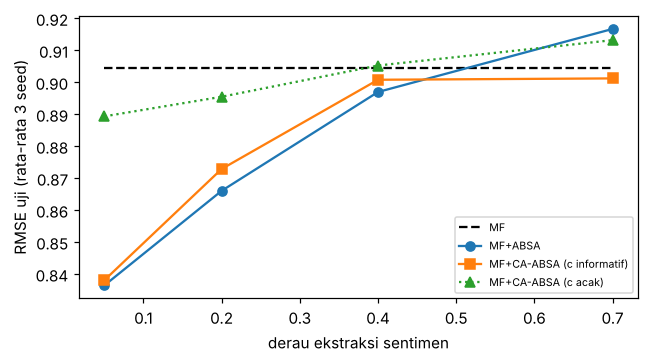

In [7]:
fig, ax = plt.subplots(figsize=(6, 3.4))
for kol, gaya in zip(tabel.columns, ("k--", "o-", "s-", "^:")):
    ax.plot(tabel.index, tabel[kol], gaya, label=kol)
ax.set(xlabel="derau ekstraksi sentimen", ylabel="RMSE uji (rata-rata 3 seed)")
ax.legend(fontsize=7)
fig.tight_layout()

# klaim yang diuji (kualitatif): sentimen yang bersih membantu; manfaat itu menyusut seiring derau
gain = tabel["MF"] - tabel["MF+ABSA"]
assert gain.loc[0.05] > 0.03 and gain.loc[0.05] > gain.loc[0.7]
# konfidens acak tidak lebih baik daripada konfidens informatif secara rata-rata
assert tabel["MF+CA-ABSA (c informatif)"].mean() <= tabel["MF+CA-ABSA (c acak)"].mean()

**Interpretasi (simulasi dengan asumsi di atas).**

1. Sentimen aspek yang bersih (derau 0,05) menurunkan RMSE jauh di bawah MF. Manfaatnya menyusut saat derau naik. Pada derau tinggi MF+ABSA bahkan bisa lebih buruk daripada MF, karena suku aspek memasukkan derau ke prediksi.
2. Gerbang dengan konfidens **informatif** meredam derau itu. Pada derau tertinggi ia menyelamatkan model dari kerugian MF+ABSA. Pada derau rendah ia sedikit mengorbankan sinyal, karena `g(c) < 1` ikut mengecilkan sentimen yang sebenarnya benar.
3. Gerbang dengan konfidens **acak** tidak bisa membedakan sentimen yang andal dari yang tidak, sehingga hampir selalu lebih buruk daripada konfidens informatif. **Gerbang hanya berguna bila konfidens benar-benar membawa informasi tentang keandalan.** Pada klasifikator sungguhan, itu bergantung pada kalibrasi softmax, yang tidak dijamin.

Selisih antara MF+ABSA dan MF+CA-ABSA kecil (di bawah satu persen pada derau rendah dan menengah). Karena itu bab 3.8 memakai uji berpasangan dan banyak seed. Lihat notebook berikutnya.

### Eksperimen C: apakah bobot aspek pengguna terpelajar benar?

Karena datanya simulasi, kita tahu bobot aspek pengguna yang sebenarnya (`a`). Ukur korelasi antara `A` hasil pelatihan dan `a` yang sebenarnya.

In [8]:
rows = []
for noise in (0.05, 0.2, 0.4, 0.7):
    kor = {"ABSA": [], "CA-ABSA": []}
    for sd in (0, 1, 2):
        Dn = simulasi_ulasan(noise=noise, seed=sd)
        tr, _ = bagi(len(Dn["r"]), sd)
        for nama, S in (("ABSA", Dn["s"]), ("CA-ABSA", gate(Dn["c"]) * Dn["s"])):
            m = AspectMF(Dn["m"], Dn["n"], Dn["K"], seed=sd).fit(Dn["u"][tr], Dn["i"][tr], Dn["r"][tr], S[tr])
            kor[nama].append(np.corrcoef(m.A.ravel(), Dn["a"].ravel())[0, 1])
    rows.append({"noise": noise, **{k: float(np.mean(v)) for k, v in kor.items()}})
kor_tab = pd.DataFrame(rows).set_index("noise")
print(kor_tab.round(3))
assert kor_tab["ABSA"].is_monotonic_decreasing

        ABSA  CA-ABSA
noise                
0.05   0.609    0.606
0.20   0.503    0.472
0.40   0.345    0.219
0.70   0.217    0.135


**Interpretasi.** Pada simulasi ini bobot aspek pengguna makin sulit dipulihkan saat derau naik. Gerbang **tidak** memperbaiki pemulihan bobot itu. Ia bahkan sedikit menurunkannya, karena `g(c) · s` mengecilkan sinyal yang dipakai untuk menaksir `a`. Jadi manfaat gerbang pada RMSE (Eksperimen B) tidak otomatis berarti pemahaman preferensi pengguna lebih baik. Itu hasil simulasi ini, bukan hukum umum. Kesimpulan seperti itu perlu diuji pada data nyata dengan label preferensi aspek yang valid, jika ada.

## Pertanyaan refleksi

1. Mengapa gerbang memakai `g(c) · s` dan bukan menarik `s` ke 0,5 (netral) saat konfidens rendah? Apa konsekuensinya bagi tanda sumbangan aspek?
2. Ubah `conf_informatif=False` dan ulangi Eksperimen B pada derau 0,7. Apa yang berubah?
3. Bagaimana Anda akan memeriksa bahwa konfidens softmax klasifikator BERT sungguhan informatif? (Petunjuk: kurva kalibrasi.)